In [3]:
from scipy import integrate

import index_function as index_function

from itertools import combinations

import networkx as nx
import scipy as scipy
import numpy as np
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
import random
import csv
import pandas as pd
import math
import importlib
import scienceplots
import pickle
from tqdm import tqdm
from matplotlib.ticker import MaxNLocator

import function_dynamics as fd
from scipy.integrate import odeint
from scipy import integrate
np.set_printoptions(threshold=100)
importlib.reload(index_function)
importlib.reload(fd)
from scipy.special import rel_entr

In [5]:
import pickle
with open('G_fig1.pkl', 'rb') as f:
    G = pickle.load(f)

In [7]:
def collective_influence(G, l=2):
    """
    计算networkx图G中所有节点的Collective Influence (CI)。
    
    参数：
        G : networkx.Graph
            输入无向图
        l : int
            邻域半径
    
    返回：
        ci_dict : dict
            节点 -> CI值的字典
    """
    ci_dict = {}
    
    for node in G.nodes():
        k_i = G.degree(node)
        
        # 找到正好距离l的节点
        l_hop_neighbors = []
        for neighbor, dist in nx.single_source_shortest_path_length(G, node, cutoff=l).items():
            if dist == l:
                l_hop_neighbors.append(neighbor)
        
        sum_kj_minus1 = sum(G.degree(j) - 1 for j in l_hop_neighbors)
        ci = (k_i - 1) * sum_kj_minus1
        
        ci_dict[node] = ci
    
    return ci_dict

In [9]:
def index_value(graph):
    BNC = index_function.regular_betweeness_centrality(graph)
    CNC = index_function.regular_coreness(graph)
    
    EVC = index_function.regular_eigenector_centrality(graph)
    PRC = index_function.regular_page_rank(graph)
    CI = collective_influence(graph)

    CC = index_function.regular_closeness_centrality(graph)
    

    index_result = [BNC, CNC, EVC, PRC, CI, CC]
    return index_result

In [11]:
index_G = index_value(G)

regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality


In [13]:
index_BNC = index_G[0]
index_CNC = index_G[1]

index_EVC = index_G[2]
index_PRC = index_G[3]
index_CI = index_G[4]

In [15]:
def sis(f,g,graph):
    t0 = 0
    Adj = nx.to_numpy_array(graph)
    y0 = 1 * np.ones(np.shape(Adj)[0])
    termination = True
    m_s = 0.001
    while termination:
        t_max = t0 + 5
        t_span = (t0, t_max)
        result1 = integrate.solve_ivp(fd.func_sis,
                             t_span,
                             y0,
                             method='RK45',args=(f, g,Adj),
                             dense_output=True,
                             max_step=m_s)
        if (np.max(np.abs(result1.y[:, -1] - result1.y[:, -2]))/m_s < 1e-3) or (t_max>200):
            termination = 1 - termination
        else:
            t0 = t_max
            y0 = result1.y[:, -1]
    return [termination,t_max,result1.y[:, -1]]

In [17]:
t_max = 0 + 20
t_span = (0, t_max)
G = G
A = nx.to_numpy_array(G)
y0 = 1*np.ones(np.shape(A)[0])
# result = integrate.solve_ivp(func_sis,
#                              t_span,
#                              y0,
#                              method='RK45',args=(-5,0.385,A1,B1),
#                              dense_output=True,
#                              max_step=0.1)
f = -1
g = 0.3
state = integrate.solve_ivp(fd.func_sis,
                             t_span,
                             y0,
                             method='RK45',args=(f, g,A),
                             dense_output=True,
                             max_step=0.001)

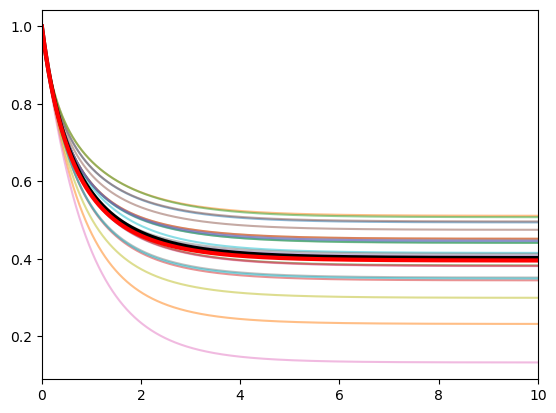

In [19]:
for i in range(A.shape[0]):
    #     plt.plot(result.t,np.log10(result.y[i,:]))
    plt.plot(state.t, (state.y[i, :]), alpha=0.5)
plt.plot(state.t, np.mean(state.y,axis=0), c = 'k', linewidth=3, label = '')
zz = state.y[[18, 17, 5]]
plt.plot(state.t, np.mean(zz,axis=0), c = 'r', linewidth=3)
plt.xlim([0,10])
# plt.savefig('./figure/state.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [21]:
def kl_(x,y):
    from scipy.stats import entropy
    # 构建直方图并归一化为概率分布
    bins = 50
    px, _ = np.histogram(x, bins=bins, density=True)
    py, _ = np.histogram(y, bins=bins, density=True)
    
    # 避免出现 log(0) 或除以 0 的情况：加一个小常数
    px += 1e-10
    py += 1e-10
    
    # 归一化使其总和为1（概率分布）
    px = px / px.sum()
    py = py / py.sum()
    
    # 计算 KL 散度：D_KL(P || Q)
    kl = entropy(px, py)
    return kl

In [23]:
def one_network_index(graph_name):
    filename1 = f"./data/graph_{graph_name}.pkl"
    
    with open(filename1, "rb") as f:
        G = pickle.load(f)

    index_G = index_value(G)
    index_dict = dict()
    index_dict['BNC'] = list(index_G[0].values())
    index_dict['CNC'] = list(index_G[1].values())
    index_dict['EVC'] = list(index_G[2].values())
    index_dict['PRC'] = list(index_G[3].values())
    index_dict['CI'] = list(index_G[4].values())
    return G, index_dict

In [25]:
def one_network_stats_result_adaptive_num(G,choice):
    # filename1 = f"./data/graph_{graph_name}.pkl"
    
    # with open(filename1, "rb") as f:
    #     G = pickle.load(f)
    avg_neighbor_deg = nx.average_neighbor_degree(G)
    degree = dict(G.degree())
    

    index_G = index_value(G)
    index_BNC = index_G[0]
    index_CNC = index_G[1]
    
    index_EVC = index_G[2]
    index_PRC = index_G[3]


    if choice=='adaptive':
        num = int(np.floor(np.log(G.number_of_nodes())))
    else:
        num = choice
    ind = single_run_wrapper(index_EVC, index_PRC, index_BNC, degree, avg_neighbor_deg,num)
    return ind

In [27]:
from joblib import Parallel, delayed
import numpy as np
from tqdm import tqdm

def single_run_wrapper(evc, prc, bnc, degree, knn, num):
    selected_indices = select_representatives_by_n(np.array(list(evc.values())), num)
    selected_indices1 = select_representatives_by_n(np.array(list(prc.values())), num)
    selected_indices2 = select_representatives_by_n(np.array(list(bnc.values())), num)
    selected_indices3 = select_representatives_by_n(np.array(list(degree.values())), num)
    selected_indices4 = select_representatives_by_n(np.array(list(knn.values())), num)

    return (
        selected_indices,
        selected_indices1,
        selected_indices2,
        selected_indices3,
        selected_indices4)

def select_representatives_by_n(x, n):
    """
    把x按n个分位区间划分，从每个区间选择最接近区间均值的元素，返回这些元素在原数组中的索引。

    参数：
    x: array-like，一维数组
    n: int，划分区间数
    
    返回：
    indices: list，所选元素在原数组中的索引
    """
    x = np.asarray(x)

    # 计算n个均匀分位数划分点
    split_points = np.quantile(x, np.linspace(0, 1, n + 1))
    split_points = np.unique(split_points)

    # 防止边界问题
    # split_points[0] -= 1e-8
    # split_points[-1] += 1e-8

    # 打标签
    labels = pd.cut(x, bins=split_points, labels=False, include_lowest=True)

    indices = []
    for i in range(n):
        group_idx = np.where(labels == i)[0]
        if len(group_idx) == 0:
            indices.append(None)  # 当前区间没元素
        else:
            group = x[group_idx]
            mean_val = group.mean()
            closest_idx_in_group = np.argmin(np.abs(group - mean_val))
            indices.append(group_idx[closest_idx_in_group])

    indices = [x for x in indices if x is not None]
    return indices

In [29]:
one_network_stats_result_adaptive_num(G,'adaptive')

regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality


([18, 17, 5], [7, 13, 15], [3, 13, 15], [3, 8, 0], [6, 19, 18])

In [31]:
def MI(x,y):
    from sklearn.metrics import mutual_info_score
    
    # 将连续值做离散化（如用分箱）
    x_bins = np.digitize(x, bins=np.histogram_bin_edges(x, bins='auto'))
    y_bins = np.digitize(y, bins=np.histogram_bin_edges(y, bins='auto'))
    
    mi = mutual_info_score(x_bins, y_bins)

    return mi

In [33]:
import numpy as np
import pandas as pd
from scipy.stats import wasserstein_distance

def stratified_wd_analysis(x, y, n_layers=10):
    """
    按 x 分层，计算每层 y 分布与整体 y 分布的 Wasserstein 距离。
    如果 wd_threshold 给定，则标记 WD > threshold 的层为“代表性差”。
    
    参数:
        x: 一维数组或序列，作为分层依据
        y: 一维数组或序列，目标变量
        n_layers: 分层数，默认10层
        wd_threshold: WD 阈值（float），超过则认为该层代表性差，默认 None 不做标记
    
    返回:
        df_result: DataFrame，列包括
            - layer: 层编号（从0开始）
            - x_range: (min, max) 每层 x 范围
            - wd: 该层 y 与整体 y 的 Wasserstein 距离
            - is_poor_repr: 是否代表性差（bool，只有设置阈值时有效）
    """
    x = np.asarray(x)
    y = np.asarray(y)
    
    # 计算分层区间（百分位数分层）
    bins = np.percentile(x, np.linspace(0, 100, n_layers + 1))
    
    wd_list = []
    x_ranges = []
    
    y_global = y
    mad_global = np.median(np.abs(y_global - np.median(y_global)))
    
    for i in range(n_layers):
        # 选出该层对应的 x 范围内样本索引
        mask = (x >= bins[i]) & (x <= bins[i+1]) if i == n_layers - 1 else (x >= bins[i]) & (x < bins[i+1])
        y_layer = y[mask]
        
        # 防止该层无样本
        if len(y_layer) == 0:
            wd = np.nan
        else:
            wd = np.median(np.abs(y_layer - np.median(y_layer)))/mad_global #wasserstein_distance(y_layer, y_global)  np.var(y_layer)/np.var(y_global)
        
        wd_list.append(wd)
        x_ranges.append((bins[i], bins[i+1]))
        
    df_result = pd.DataFrame({
        'layer': np.arange(n_layers),
        'x_range': x_ranges,
        'wd': wd_list,
    })
    
    # if wd_threshold is not None:
    #     df_result['is_poor_repr'] = df_result['wd'] > wd_threshold
    # else:
    #     df_result['is_poor_repr'] = False
    
    return df_result, np.nanmean(wd_list)

In [35]:
def rank_corr(graph_name,dynamic):
    from scipy.stats import spearmanr
    from scipy.stats import kendalltau
    from scipy.stats import wasserstein_distance
    filename1 = f"./data/graph_{graph_name}.pkl"
    
    with open(filename1, "rb") as f:
        G = pickle.load(f)
    avg_neighbor_deg = nx.average_neighbor_degree(G)
    degree = dict(G.degree())
    

    index_G = index_value(G)
    index_BNC = index_G[0]
    index_CNC = index_G[1]
    
    index_EVC = index_G[2]
    index_PRC = index_G[3]
    index_CI = index_G[4]
    index_CC = index_G[5]

    filename2 = f"./data/{dynamic}/result_{graph_name}.pkl"

    with open(filename2, "rb") as f:
        result_G = pickle.load(f)
    weights = [result_G[i][3] for i in range(len(result_G))]

    result_matrix_G = np.zeros((G.number_of_nodes(),len(weights)))

    index_all = [index_EVC, index_CI, index_BNC, degree, avg_neighbor_deg, index_PRC, index_CC]
    df_s_c = pd.DataFrame(columns=['EVC', 'CI', 'BNC', 'degree', 'knn','PRC', 'CC'])
    df_k_c = pd.DataFrame(columns=['EVC', 'CI', 'BNC', 'degree', 'knn','PRC', 'CC'])
    df_wd = pd.DataFrame(columns=['EVC', 'CI', 'BNC', 'degree', 'knn','PRC', 'CC'])
    # k=0
    for k in range(len(index_all)):
        x = list(index_all[k].values())
        s_c = []
        k_c = []
        wd = []
        for i in range(len(weights)):
            y = result_G[i][4]
            if np.mean(y)>0:
                s_c.append(MI(x,y))
                k_c.append(spearmanr(x,y)[0])
                wd.append(stratified_wd_analysis(x, y, n_layers=10)[1])
            else:continue
    
        df_s_c[df_s_c.columns[k]] = s_c
        df_k_c[df_k_c.columns[k]] = k_c
        df_wd[df_wd.columns[k]] = wd
        # k = k+1
    # plt.scatter(list(index_EVC.values()) ,list(index_BNC.values()) )
    return [df_s_c,df_k_c, df_wd]

In [37]:
zz = []
name = [ "arenas_email", "FlyBi", "usair"]
dynamic_name = ['sis', 'grn', 'neuronal']
for graph_name in name:
    for dynamic in dynamic_name:
        zz.append(rank_corr(graph_name,dynamic))

regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality


/home/qinjiajie/anaconda3/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
/tmp/xpython_35820/1240291339.py:44: RuntimeWarning: invalid value encountered in scalar divide
  wd = np.median(np.abs(y_layer - np.median(y_layer)))/mad_global #wasserstein_distance(y_layer, y_global)  np.var(y_layer)/np.var(y_global)
/tmp/xpython_35820/1240291339.py:60: RuntimeWarning: Mean of empty slice
  return df_result, np.nanmean(wd_list)
/home/qinjiajie/anaconda3/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
/tmp/xpython_35820/1240291339.py:44: RuntimeWarning: invalid value encountered in scalar divide
  wd = np.median(np.abs(y_layer - np.median(y_layer)))/mad_global #wasserstein_distanc

regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality


In [39]:
MI_all = 0
for i in range(len(zz)):
    MI_all = MI_all  + zz[i][0].mean().to_frame().T

MI_all = MI_all/len(zz)

In [41]:
spearmanr_all = 0
for i in range(len(zz)):
    spearmanr_all = spearmanr_all  + zz[i][1].mean().to_frame().T

spearmanr_all = spearmanr_all/len(zz)

In [43]:
mad_all = 0
for i in range(len(zz)):
    mad_all = mad_all  + zz[i][2].mean().to_frame().T

mad_all = 1/(mad_all/len(zz))

In [45]:
mad_all

,EVC,CI,BNC,degree,knn,PRC,CC
0,0.657977,0.340472,0.5327,0.295684,0.683004,0.868864,1.073495


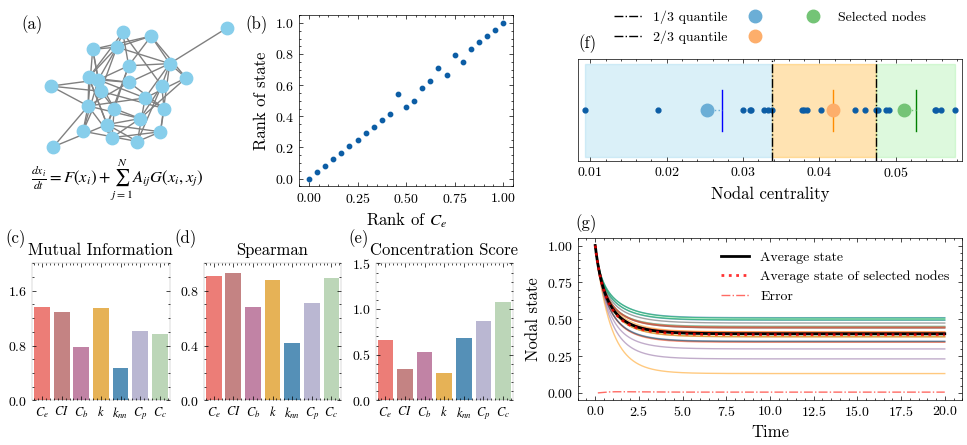

In [47]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display, Math
from scipy.stats import rankdata
import string
import seaborn as sns

with plt.style.context(['science', 'no-latex']):
    plt.rcParams["text.usetex"] = False  # 关闭 LaTeX 引擎
    plt.rcParams['mathtext.fontset'] = 'stix'  # 更现代的 math font
    # plt.rcParams['font.family'] = 'monospace'
    # 创建画布和 GridSpec，设置列宽比例：左边宽度是右边的 2 倍
    fig = plt.figure(figsize=(12, 5))
    gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.8], height_ratios=[1, 0.8], wspace=0.15, hspace=0.5)
    
    # 合并左边两格（row=0 and 1, col=0）
    gs_1 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0,0], width_ratios=[1, 1], hspace=0.3,wspace=0.25)
    ####################################################### 先将第一列拆成6份，取出中间4份放置图1   （a）
    gs_left = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=gs_1[0], height_ratios=[1,1,0.2], hspace=0.3)
    ax_big = fig.add_subplot(gs_left[0:2])  # 冒号表示所有行，col=0
    
    # 示例内容
    pos = nx.spring_layout(G, seed=42)
    
        # 再传给 nx.draw
    nx.draw(G, pos=pos, with_labels=False, node_color='skyblue', edge_color='gray', node_size=80, ax = ax_big)
    # ax_big.set_title('Network structure')
    ax_big.text(0.05, 1, '(a)', transform=ax_big.transAxes,
            ha='right', va='top', fontsize=12)
    
    ################################################################   (a)
    ax_small = fig.add_subplot(gs_left[2])  # 冒号表示所有行，col=0
    ax_small.set_frame_on(False)        # 整个坐标轴框架隐藏（类似上面做法）
    ax_small.get_xaxis().set_visible(False)
    ax_small.get_yaxis().set_visible(False)
    ax_small.text(0.4, 0.5, r'$\frac{dx_i}{dt} = F(x_i)+\sum_{j=1}^NA_{ij}G(x_i,x_j)$', transform=ax_small.transAxes, ha='center', va='center', fontsize=12)
    
    # #############################################################(b)
    ax_right = fig.add_subplot(gs_1[1])
    y = state.y[:,-1]
    y_percentile = (rankdata(y) - 1) / (len(y) - 1)
    x = list(index_EVC.values())
    x_percentile = (rankdata(x) - 1) / (len(x) - 1)
    ax_right.scatter(x_percentile, y_percentile, s=10)
    ax_right.set_xlabel('Rank of '  + r'$C_e$', fontsize=12)
    ax_right.set_ylabel('Rank of state', fontsize=12)
    ax_right.text(-0.15, 1, '(b)', transform=ax_right.transAxes,
            ha='right', va='top', fontsize=12)
    
    
    # ######################################################################### (c-d-f)
    corr_ = [MI_all, spearmanr_all, mad_all]
    corr_name = ['Mutual Information', 'Spearman', 'Concentration Score']
    custom_colors = ['#FF6B64', '#CF7878', '#CB79A6', '#FEB83E',  '#4493C8', '#B6B3D6', '#B8DBB3']
    ylim_set = [[0,2],[0,1],[0,1.5]]
    gs_2 = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1,0], width_ratios=[1, 1, 1], hspace=0.3,wspace=0.25)
    for i in range(3):
        ax_1 = fig.add_subplot(gs_2[i])
        sns.barplot(data=corr_[i], ax=ax_1, palette=custom_colors)
        # axs[i].set_yscale('log')  # 将y轴改为对数坐标
        ax_1.set_title(corr_name[i])
        new_labels = [r'$C_e$', r'$CI$', r'$C_b$', r'$k$', r'$k_{nn}$', r'$C_p$', r'$C_c$']
        ax_1.set_xticklabels(new_labels, fontsize=9)
        # ax_1.set_xlabel('Index', fontsize=12)
        ax_1.set_ylim(ylim_set[i])
        ax_1.yaxis.set_major_locator(MaxNLocator(nbins=3))
        ax_1.spines['bottom'].set_linewidth(0.1)
        ax_1.spines['left'].set_linewidth(0.1)
        ax_1.spines['top'].set_linewidth(0.1)
        ax_1.spines['right'].set_linewidth(0.1)
        ax_1.text(-0.05, 1.25, '(%s)' % string.ascii_lowercase[i+2], transform=ax_1.transAxes,ha='right', va='top', fontsize=12)
    
    
    
    ######################################################## g 策略
    gs_2 = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[:,1], height_ratios=[0.9,1], hspace=0.5)
    
    # gs_right = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=gs[0,1], height_ratios=[1, 3, 1], hspace=0.3)
    
    ax = fig.add_subplot(gs_2[0])
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width , box.height* 0.7])  # 压缩宽度
    x = np.array(x)
    q1 = np.quantile(x, 1/3)
    q2 = np.quantile(x, 2/3)
    
    
    y_levels = [0.2, 0.2, 0.2]  # 所有条的高度都相等
    # 绘制每个分位区间为彩色区域
    ax.fill_betweenx([0, y_levels[0]], x.min(), q1, color='skyblue', alpha=0.3) # , label='low area' 
    ax.fill_betweenx([0, y_levels[1]], q1, q2, color='orange', alpha=0.3) # , label='median area'
    ax.fill_betweenx([0, y_levels[2]], q2, x.max(), color='lightgreen', alpha=0.3) # , label='high area'
    
    # 标出分位边界线
    ax.axvline(q1, color='black', linestyle='-.', label='1/3 quantile')
    ax.axvline(q2, color='black', linestyle='-.', label='2/3 quantile')
    
    ax.scatter(x, 0.1*np.ones(len(x_percentile)),s=12)
    
    low = x[x <= q1]
    mid = x[(x > q1) & (x <= q2)]
    high = x[x > q2]
    
    # 各区间均值
    mean_low = np.mean(low)
    mean_mid = np.mean(mid)
    mean_high = np.mean(high)
    
    # 均值位置标注
    ax.axvline(mean_low,ymin=0.3, ymax=0.7, color='blue', linestyle='-', linewidth=1) # , label='low average'
    ax.axvline(mean_mid,ymin=0.3, ymax=0.7, color='darkorange', linestyle='-', linewidth=1) # , label='median average'
    ax.axvline(mean_high,ymin=0.3, ymax=0.7, color='green', linestyle='-', linewidth=1) # , label='high average'
    
    # 找出每个区间内距离均值最近的3个点
    def closest_points(data, mean, n=1):
        return data[np.argsort(np.abs(data - mean))[:n]]
    
    pts_low = closest_points(low, mean_low)
    pts_mid = closest_points(mid, mean_mid)
    pts_high = closest_points(high, mean_high)
    # 设置 y 水平显示区域
    y_base = 0.1
    dy = 0.1  # 点到均值的连线高度间隔
    # 标记并连线
    def annotate_points(points, mean, color, y_level,label):
        for i, val in enumerate(points):
            y = y_level - i * dy
            ax.plot(val, y, 'o', color=color,markersize=9, label=label) 
            ax.plot([val, mean], [y, y], color=color, linestyle='dotted')  # 横线连接点与均值
    
    # 标注每个区间的最近点
    annotate_points(pts_low, mean_low, '#6BAED6', y_base, ' ')
    annotate_points(pts_mid, mean_mid, '#FDAE6B', y_base,' ')
    annotate_points(pts_high, mean_high, '#74C476', y_base,'Selected nodes')
    # 美化图形
    ax.set_yticks([])
    ax.set_xlabel('Nodal centrality', fontsize=12)
    # ax.set_title('x的分位数区间划分')
    ax.legend(loc='upper center',
              bbox_to_anchor=(0.5, 1.6),
              columnspacing=1,
              ncol=3,  # 横向排列两列
              frameon=False)  # 可选：去掉图例边框
    ax.set_xlim(x.min()-0.001, x.max()+0.001)
    ax.text(0.05, 1.25, '(f)', transform=ax.transAxes,
            ha='right', va='top', fontsize=12)
    
    #######################################################################
    ax_top_right = fig.add_subplot(gs_2[1])
    for i in range(A.shape[0]):
        #     plt.plot(result.t,np.log10(result.y[i,:]))
        ax_top_right.plot(state.t, (state.y[i, :]), alpha=0.5)
    ax_top_right.set_xlabel('Time', fontsize=12)
    ax_top_right.set_ylabel('Nodal state', fontsize=12)
    
    ax_top_right.text(0.05, 1.15, '(g)', transform=ax_top_right.transAxes,
            ha='right', va='top', fontsize=12)
    
    ax_top_right.plot(state.t, np.mean(state.y,axis=0), c = 'k', linewidth=2, label = 'Average state')
    uu = state.y[[18, 17, 5]]
    ax_top_right.plot(state.t, np.mean(uu,axis=0), c = 'r', linewidth=2, label = 'Average state of selected nodes', linestyle='dotted', alpha=0.8)
    ax_top_right.plot(state.t[150:], np.abs(np.mean(uu,axis=0)-np.mean(state.y,axis=0))[150:], c = custom_colors[0], linewidth=1, label = 'Error', linestyle='-.')
    # ax_top_right.set_yscale('log')
    # ax_top_right.set_yscale('log')
    ax_top_right.legend(fontsize = 10)
    
    
    # plt.savefig('./figure/Figure_1_revised.pdf', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()